# Does the world produce enough food to feed everyone?

Public-health study for the FAO (OpenClassrooms Data Analyst path, project 4), based on four FAO files:
population (2013–2018), food balance sheets (2017), food aid (2013–2016) and undernourishment (three-year averages, 2012–2014 to 2017–2019).

**Case study:** https://axeldrtdata.github.io/works/global-food-security/

> **Note on this version.** The notebook was translated into English and re-run for my portfolio in October 2026.
> The FAO files themselves are in French, so country, product and column names stay in French.
> On a second look at the data, I also corrected a few points, each one marked in the notebook:
> - quantities from the food balance sheets are in **thousands of tonnes**, so multiplying them by 1,000 gives **tonnes**, not kilograms;
> - the number of countries in each file is now counted on the right file;
> - three country names did not match between files (United Kingdom, Czechia, Eswatini), so those countries were silently dropped by the joins;
> - section 5 adds checks on data coverage that change how two conclusions should be read.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 1 - Import the libraries and load the files</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Import the libraries</h3>
</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Load the CSV files</h3>
</div>

In [2]:
population = pd.read_csv('../data/population.csv')
dispo_alimentaire = pd.read_csv('../data/dispo_alimentaire.csv')   # food balance sheets
aide_alimentaire = pd.read_csv('../data/aide_alimentaire.csv')     # food aid
sous_nutrition = pd.read_csv('../data/sous_nutrition.csv')         # undernourishment

**Correction: harmonise country names.** The food balance sheets write `Royaume-Uni` and `Tchéquie (la)`, while the population
and undernourishment files use the full official names, and the food-aid file still uses the old name `Swaziland` for Eswatini.
Without this step, those countries silently disappear from every join.

In [3]:
dispo_alimentaire['Zone'] = dispo_alimentaire['Zone'].replace({
    'Royaume-Uni': "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord",
    'Tchéquie (la)': 'Tchéquie',
})
aide_alimentaire['Pays bénéficiaire'] = aide_alimentaire['Pays bénéficiaire'].replace({'Swaziland': 'Eswatini'})

# Check: every country of the food balance sheets now exists in the population file
print(sorted(set(dispo_alimentaire['Zone']) - set(population['Zone'])))

[]


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 2 - Explore the files</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Population</h3>
</div>

In [4]:
print(f"The table has {population.shape[0]} rows and {population.shape[1]} columns.")
population.info()

The table has 1416 rows and 3 columns.
<class 'pandas.DataFrame'>
RangeIndex: 1416 entries, 0 to 1415
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Zone    1416 non-null   str    
 1   Année   1416 non-null   int64  
 2   Valeur  1416 non-null   float64
dtypes: float64(1), int64(1), str(1)
memory usage: 33.3 KB


In [5]:
population.head(5)

,Zone,Année,Valeur
0,Afghanistan,2013,32269.589
1,Afghanistan,2014,33370.794
2,Afghanistan,2015,34413.603
3,Afghanistan,2016,35383.032
4,Afghanistan,2017,36296.113


In [6]:
# Population is given in thousands: convert it to people
population['Valeur'] = population['Valeur'] * 1000
population = population.rename(columns={'Valeur': 'Population'})
population['Population'] = population['Population'].astype(int)
population.head(5)

,Zone,Année,Population
0,Afghanistan,2013,32269589
1,Afghanistan,2014,33370794
2,Afghanistan,2015,34413603
3,Afghanistan,2016,35383032
4,Afghanistan,2017,36296113


In [7]:
print(f"The dataset starts in {population['Année'].min()} and ends in {population['Année'].max()}.")
print(f"It lists {population['Zone'].nunique()} countries and territories.")

The dataset starts in 2013 and ends in 2018.
It lists 236 countries and territories.


**Conclusion:** the population file has 1,416 rows and 3 columns, and gives the population of 236 countries and territories from 2013 to 2018.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Food balance sheets (food availability)</h3>
</div>

In [8]:
print(f"The table has {dispo_alimentaire.shape[0]} rows and {dispo_alimentaire.shape[1]} columns.")
dispo_alimentaire.info()

The table has 15605 rows and 18 columns.
<class 'pandas.DataFrame'>
RangeIndex: 15605 entries, 0 to 15604
Data columns (total 18 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   Zone                                                           15605 non-null  str    
 1   Produit                                                        15605 non-null  str    
 2   Origine                                                        15605 non-null  str    
 3   Aliments pour animaux                                          2720 non-null   float64
 4   Autres Utilisations                                            5496 non-null   float64
 5   Disponibilité alimentaire (Kcal/personne/jour)                 14241 non-null  float64
 6   Disponibilité alimentaire en quantité (kg/personne/an)         14015 non-null  float64
 7   Disponibilité de matière gra

In [9]:
dispo_alimentaire.head(5)

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53.0,NaN,NaN,53.0,NaN,53.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41.0,2.0,40.0,39.0,2.0,3.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82.0,NaN,82.0,82.0,NaN,NaN,NaN,NaN,NaN


In [10]:
# Replace missing values with 0 (a missing quantity means nothing recorded for that product)
dispo_alimentaire = dispo_alimentaire.fillna(0)

# Correction: these columns are in THOUSANDS OF TONNES, so multiplying by 1,000 gives TONNES (not kilograms)
columns_tonnes = ['Aliments pour animaux', 'Autres Utilisations', 'Disponibilité intérieure', 'Exportations - Quantité',
                  'Importations - Quantité', 'Nourriture', 'Pertes', 'Production', 'Semences', 'Traitement',
                  'Variation de stock']
dispo_alimentaire[columns_tonnes] = dispo_alimentaire[columns_tonnes] * 1000
dispo_alimentaire.head(5)

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,0.77,53000.0,0.0,0.0,53000.0,0.0,53000.0,0.0,0.0,0.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,0.02,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,0.03,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,0.05,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0


In [11]:
# Correction: count the countries in this file (the original cell counted the population file)
print(f"The food balance sheets cover {dispo_alimentaire['Zone'].nunique()} countries.")

The food balance sheets cover 174 countries.


**Conclusion:** the food balance sheets describe the year 2017. The file has 15,605 rows and 18 columns and covers **174 countries**
(not 236, as first written: the count was made on the population file). For each country and product, it gives the
calories, proteins and fats available per person, the origin of the product (plant or animal) and how the domestic supply is used.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Food aid</h3>
</div>

In [12]:
print(f"The table has {aide_alimentaire.shape[0]} rows and {aide_alimentaire.shape[1]} columns.")
aide_alimentaire.info()

The table has 1475 rows and 4 columns.
<class 'pandas.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Pays bénéficiaire  1475 non-null   str  
 1   Année              1475 non-null   int64
 2   Produit            1475 non-null   str  
 3   Valeur             1475 non-null   int64
dtypes: int64(2), str(2)
memory usage: 46.2 KB


In [13]:
aide_alimentaire.head(5)

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


In [14]:
# Food aid is in tonnes: convert it to kilograms
aide_alimentaire = aide_alimentaire.rename(columns={'Pays bénéficiaire': 'Zone', 'Valeur': 'Aide alimentaire'})
aide_alimentaire['Aide alimentaire'] = aide_alimentaire['Aide alimentaire'] * 1000
aide_alimentaire.head(5)

,Zone,Année,Produit,Aide alimentaire
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


In [15]:
# Correction: count the countries in this file
print(f"Food aid is recorded for {aide_alimentaire['Zone'].nunique()} recipient countries.")
print(f"The dataset starts in {aide_alimentaire['Année'].min()} and ends in {aide_alimentaire['Année'].max()}.")

Food aid is recorded for 76 recipient countries.
The dataset starts in 2013 and ends in 2016.


**Conclusion:** the food-aid file has 1,475 rows and 4 columns. It gives the quantity of food aid received, in kilograms after conversion,
by **76 recipient countries** between 2013 and 2016.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.4 - Undernourishment</h3>
</div>

In [16]:
print(f"The table has {sous_nutrition.shape[0]} rows and {sous_nutrition.shape[1]} columns.")
sous_nutrition.info()

The table has 1218 rows and 3 columns.
<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Zone    1218 non-null   str  
 1   Année   1218 non-null   str  
 2   Valeur  624 non-null    str  
dtypes: str(3)
memory usage: 28.7 KB


In [17]:
sous_nutrition.head(5)

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


In [18]:
sous_nutrition = sous_nutrition.rename(columns={'Valeur': 'Sous nutrition'})

# Values such as '<0.1' are not numbers: errors='coerce' turns them into NaN, then NaN become 0
sous_nutrition['Sous nutrition'] = pd.to_numeric(sous_nutrition['Sous nutrition'], errors='coerce')
sous_nutrition = sous_nutrition.fillna(0)

# Values are in millions of people
sous_nutrition['Sous nutrition'] = (sous_nutrition['Sous nutrition'] * 1_000_000).astype(int)
sous_nutrition.head(5)

,Zone,Année,Sous nutrition
0,Afghanistan,2012-2014,8600000
1,Afghanistan,2013-2015,8800000
2,Afghanistan,2014-2016,8900000
3,Afghanistan,2015-2017,9700000
4,Afghanistan,2016-2018,10500000


In [19]:
print(f"The undernourishment file lists {sous_nutrition['Zone'].nunique()} countries.")
print(f"The first period is {sous_nutrition['Année'].min()} and the last one is {sous_nutrition['Année'].max()}.")

The undernourishment file lists 203 countries.
The first period is 2012-2014 and the last one is 2017-2019.


**Conclusion:** the undernourishment file has 1,218 rows and 3 columns and lists 203 countries. Each value is a three-year average,
from 2012–2014 to 2017–2019, so the period 2016–2018 is used for 2017. Section 5 shows that many of these countries have no estimate at all.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 3 - Analysis</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 - Share of undernourished people in 2017</h3>
</div>

In [20]:
sous_nutrition_2017 = sous_nutrition[sous_nutrition['Année'] == '2016-2018']
population_2017 = population[population['Année'] == 2017]

population_sous_nutrition_2017 = pd.merge(population_2017, sous_nutrition_2017, on='Zone', how='inner')
population_sous_nutrition_2017.head(5)

,Zone,Année_x,Population,Année_y,Sous nutrition
0,Afghanistan,2017,36296113,2016-2018,10500000
1,Afrique du Sud,2017,57009756,2016-2018,3100000
2,Albanie,2017,2884169,2016-2018,100000
3,Algérie,2017,41389189,2016-2018,1300000
4,Allemagne,2017,82658409,2016-2018,0


In [21]:
undernourished_2017 = population_sous_nutrition_2017['Sous nutrition'].sum()
world_population_2017 = population_sous_nutrition_2017['Population'].sum()
undernourished_share_2017 = undernourished_2017 / world_population_2017 * 100

print(f"Undernourished people in 2017: {undernourished_2017:,}")
print(f"World population in 2017: {world_population_2017:,}")
print(f"Share of undernourished people: {undernourished_share_2017:.2f} %")

Undernourished people in 2017: 535,700,000
World population in 2017: 7,543,798,769
Share of undernourished people: 7.10 %


**Conclusion:** in 2017, the world population was 7.5 billion and 535.7 million people were undernourished,
7.10% of the world population, or **one person in 14**. Section 5 explains why this figure is a floor.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 - How many people could the world's food feed?</h3>
</div>

In [22]:
# Daily energy needs, FAO source: https://www.fao.org/4/x5643f/x5643f00.htm#Contents
# Chapter 1, section B3: "2,300 to 2,500 calories ... are enough for a person to live each day"
daily_kcal_need = int((2300 + 2500) / 2)
print(f"Average daily need: {daily_kcal_need} kcal per person")

Average daily need: 2400 kcal per person


In [23]:
# Add each country's population to the food balance sheets
dispo_population_2017 = pd.merge(population_2017, dispo_alimentaire, on='Zone', how='left')

# Calories available per country and product over the year
dispo_population_2017['kcal par pays'] = (
    dispo_population_2017['Disponibilité alimentaire (Kcal/personne/jour)']
    * dispo_population_2017['Population']
    * 365
)
dispo_population_2017.head(5)

,Zone,Année,Population,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),...,Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,kcal par pays
0,Afghanistan,2017,36296113,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,...,53000.0,0.0,0.0,53000.0,0.0,53000.0,0.0,0.0,0.0,6.624041e+10
1,Afghanistan,2017,36296113,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,...,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0,1.324808e+10
2,Afghanistan,2017,36296113,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,...,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0,1.324808e+10
3,Afghanistan,2017,36296113,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00
4,Afghanistan,2017,36296113,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,...,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0,5.299232e+10


In [24]:
world_kcal = dispo_population_2017['kcal par pays'].sum()
people_fed = int(world_kcal / daily_kcal_need / 365)

print(f"Calories available in 2017: {int(world_kcal):,}")
print(f"People who could be fed: {people_fed:,}")
print(f"That is {people_fed / world_population_2017 * 100:.1f} % of the world population.")

Calories available in 2017: 7,731,489,394,689,605
People who could be fed: 8,825,901,135
That is 117.0 % of the world population.


**Conclusion:** the calories available in 2017 could feed about **8.8 billion people**, around 1.3 billion more than the world population
(the original version gave 8.7 billion, before the United Kingdom and Czechia were matched). Yet 535.7 million people were undernourished:
the world's food is not lacking, it is unevenly shared.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.3 - How many people could plant products alone feed?</h3>
</div>

In [25]:
dispo_vegetal = dispo_population_2017[dispo_population_2017['Origine'] == 'vegetale'].copy()
plant_kcal = dispo_vegetal['kcal par pays'].sum()
people_fed_plants = int(plant_kcal / daily_kcal_need / 365)

print(f"Calories available from plant products: {int(plant_kcal):,}")
print(f"People who could be fed: {people_fed_plants:,}")
print(f"That is {people_fed_plants / world_population_2017 * 100:.1f} % of the world population.")

Calories available from plant products: 6,369,070,931,881,840
People who could be fed: 7,270,628,917
That is 96.4 % of the world population.


**Conclusion:** plant products alone, about 6,400 million billion calories, would be enough to feed about **96% of the world population**.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.4 - How domestic supply is used</h3>
</div>

In [26]:
total_supply = dispo_alimentaire['Disponibilité intérieure'].sum()
print(f"Domestic supply: {total_supply / 1e9:,.2f} billion tonnes")

uses = {
    'Food': 'Nourriture', 'Processing': 'Traitement', 'Animal feed': 'Aliments pour animaux',
    'Other uses': 'Autres Utilisations', 'Losses': 'Pertes', 'Seed': 'Semences',
}
use_shares = {}
for label, column in uses.items():
    total = dispo_alimentaire[column].sum()
    use_shares[label] = total / total_supply * 100
    print(f"{label}: {total / 1e6:,.1f} million tonnes, {use_shares[label]:.2f} % of domestic supply")

Domestic supply: 9.85 billion tonnes
Food: 4,876.3 million tonnes, 49.51 % of domestic supply
Processing: 2,204.7 million tonnes, 22.38 % of domestic supply
Animal feed: 1,304.2 million tonnes, 13.24 % of domestic supply
Other uses: 865.0 million tonnes, 8.78 % of domestic supply
Losses: 453.7 million tonnes, 4.61 % of domestic supply
Seed: 154.7 million tonnes, 1.57 % of domestic supply


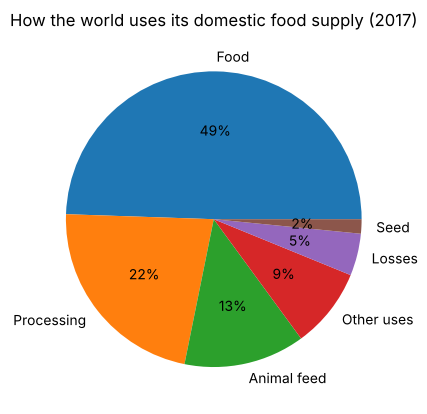

In [27]:
# Correction: the pie is now built from the computed shares instead of typed-in values
pd.Series(use_shares).plot.pie(autopct='%1.0f%%', ylabel='')
plt.title('How the world uses its domestic food supply (2017)');

**Conclusion:** only half of the domestic supply (49.5%) is eaten directly by people. Processing and animal feed together take 35%.
Losses are 4.6% of the total, but that is still **454 million tonnes** of food (the original version said 453 million kilograms,
a unit error of a factor 1,000).

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.5 - How cereals are used</h3>
</div>

In [28]:
cereals = ['Blé', 'Céréales, Autres', 'Maïs', 'Millet', 'Orge', 'Riz (Eq Blanchi)', 'Avoine', 'Seigle', 'Sorgho']
df_cereals = dispo_vegetal[dispo_vegetal['Produit'].isin(cereals)]
cereal_supply = df_cereals['Disponibilité intérieure'].sum()

cereal_shares = {label: df_cereals[column].sum() / cereal_supply * 100 for label, column in uses.items()}
for label, share in cereal_shares.items():
    print(f"{label}: {share:.2f} % of cereal supply")

Food: 42.75 % of cereal supply
Processing: 3.93 % of cereal supply
Animal feed: 36.29 % of cereal supply
Other uses: 9.75 % of cereal supply
Losses: 4.45 % of cereal supply
Seed: 2.85 % of cereal supply


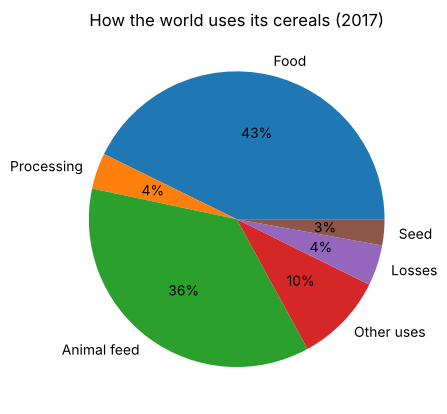

In [29]:
pd.Series(cereal_shares).plot.pie(autopct='%1.0f%%', ylabel='')
plt.title('How the world uses its cereals (2017)');

**Conclusion:** people eat 43% of the world's cereals directly, but **36% go to animal feed**.
More than a third of the world's cereals are used to produce meat, eggs and dairy.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.6 - Countries with the highest share of undernourished people in 2017</h3>
</div>

In [30]:
population_sous_nutrition_2017['Proportion %'] = (
    population_sous_nutrition_2017['Sous nutrition'] / population_sous_nutrition_2017['Population'] * 100
)
top_10_undernourished = population_sous_nutrition_2017.nlargest(10, 'Proportion %')
top_10_undernourished[['Zone', 'Population', 'Sous nutrition', 'Proportion %']]

,Zone,Population,Sous nutrition,Proportion %
78,Haïti,10982366,5300000,48.259182
157,République populaire démocratique de Corée,25429825,12000000,47.188685
108,Madagascar,25570512,10500000,41.062924
103,Libéria,4702226,1800000,38.279742
100,Lesotho,2091534,800000,38.249438
183,Tchad,15016753,5700000,37.957606
161,Rwanda,11980961,4200000,35.055619
121,Mozambique,28649018,9400000,32.810898
186,Timor-Leste,1243258,400000,32.173531
0,Afghanistan,36296113,10500000,28.928718


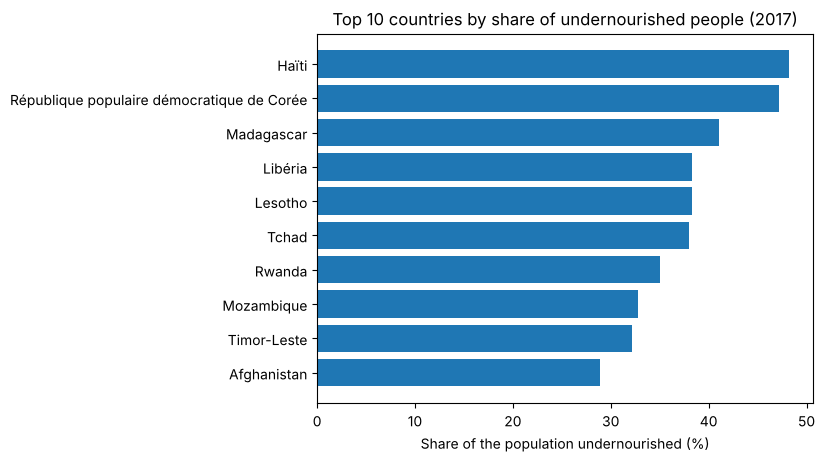

In [31]:
plt.barh(top_10_undernourished['Zone'], top_10_undernourished['Proportion %'])
plt.xlabel('Share of the population undernourished (%)')
plt.title('Top 10 countries by share of undernourished people (2017)')
plt.gca().invert_yaxis();

**Conclusion:** in the top three countries (Haiti, North Korea, Madagascar), undernourishment affects 41% to 48% of the population.
This ranking only covers countries that have an estimate (see section 5).

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.7 - Countries that received the most food aid since 2013</h3>
</div>

In [32]:
aid_by_country = (aide_alimentaire.groupby('Zone')['Aide alimentaire'].sum()
                  .sort_values(ascending=False).reset_index())
aid_by_country.head(10)

,Zone,Aide alimentaire
0,République arabe syrienne,1858943000
1,Éthiopie,1381294000
2,Yémen,1206484000
3,Soudan du Sud,695248000
4,Soudan,669784000
5,Kenya,552836000
6,Bangladesh,348188000
7,Somalie,292678000
8,République démocratique du Congo,288502000
9,Niger,276344000


**Conclusion:** 7 of the 10 countries that received the most food aid between 2013 and 2016 are in Africa, and the other 3 in Asia.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.8 - Food aid to the 5 most-aided countries, 2013 to 2016</h3>
</div>

In [33]:
aid_by_country_year = aide_alimentaire.groupby(['Zone', 'Année'])['Aide alimentaire'].sum().reset_index()
top_5 = aid_by_country.head(5)['Zone'].tolist()
aid_top_5 = aid_by_country_year[aid_by_country_year['Zone'].isin(top_5)]

# A year with no record appears as NaN, not as 0
aid_top_5.pivot(index='Zone', columns='Année', values='Aide alimentaire').div(1e6).round(1)

Année,2013,2014,2015,2016
Zone,,,,
République arabe syrienne,563.6,651.9,524.9,118.6
Soudan,330.2,321.9,17.6,NaN
Soudan du Sud,196.3,450.6,48.3,NaN
Yémen,264.8,103.8,372.3,465.6
Éthiopie,591.4,586.6,203.3,NaN


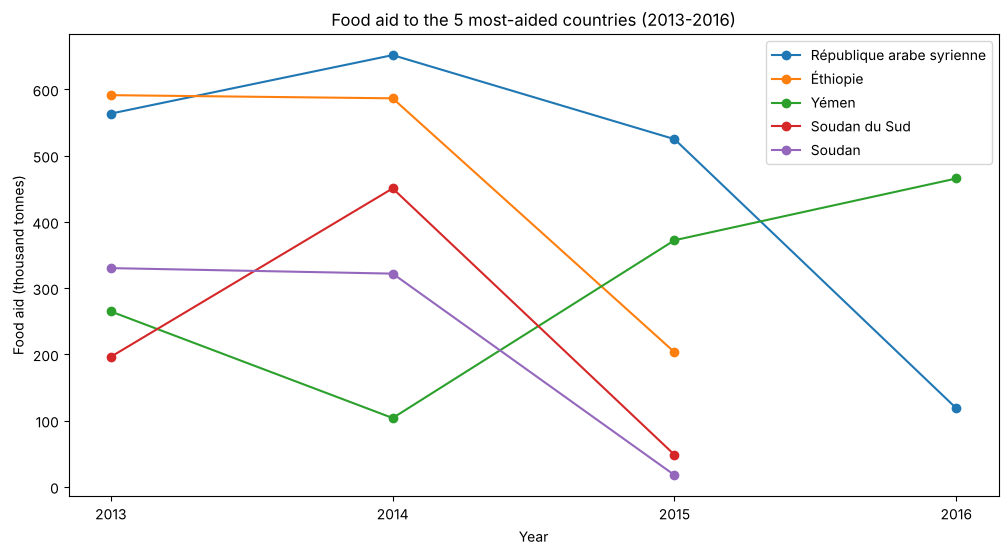

In [34]:
plt.figure(figsize=(12, 6))
for country in top_5:
    data_country = aid_top_5[aid_top_5['Zone'] == country]
    plt.plot(data_country['Année'], data_country['Aide alimentaire'] / 1e6, marker='o', label=country)
plt.xlabel('Year')
plt.ylabel('Food aid (thousand tonnes)')
plt.title('Food aid to the 5 most-aided countries (2013-2016)')
plt.legend()
plt.xticks([2013, 2014, 2015, 2016]);

**Conclusion:** aid to Ethiopia, South Sudan and Sudan fell sharply in 2015, and aid to Syria in 2016, while aid to Yemen,
after a drop in 2014, rose again from 2015. Aid follows acute crises. Ethiopia, Sudan and South Sudan have **no record at all in 2016**:
their lines stop in 2015 because the data is missing, not because aid fell to zero.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.9 - Countries with the lowest food availability per person</h3>
</div>

In [35]:
kcal_per_person = (dispo_alimentaire.groupby('Zone')['Disponibilité alimentaire (Kcal/personne/jour)'].sum()
                   .sort_values().reset_index())
kcal_per_person.head(10)

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
0,République centrafricaine,1879.0
1,Zambie,1924.0
2,Madagascar,2056.0
3,Afghanistan,2087.0
4,Haïti,2089.0
5,République populaire démocratique de Corée,2093.0
6,Tchad,2109.0
7,Zimbabwe,2113.0
8,Ouganda,2126.0
9,Éthiopie,2129.0


In [36]:
lowest_10 = kcal_per_person.nsmallest(10, 'Disponibilité alimentaire (Kcal/personne/jour)')
mean_lowest = lowest_10['Disponibilité alimentaire (Kcal/personne/jour)'].mean()
deficit = daily_kcal_need - mean_lowest
print(f"Average availability in the 10 lowest countries: {mean_lowest:.0f} kcal per person per day")
print(f"Average deficit: {deficit:.0f} kcal per person per day")

Average availability in the 10 lowest countries: 2060 kcal per person per day
Average deficit: 340 kcal per person per day


**Conclusion:** 7 of the 10 countries with the lowest food availability per person are in Africa.
On average, they lack 340 kcal per person per day compared with the 2,400 kcal need.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.10 - Countries with the highest food availability per person</h3>
</div>

In [37]:
highest_10 = kcal_per_person.nlargest(10, 'Disponibilité alimentaire (Kcal/personne/jour)')
mean_highest = highest_10['Disponibilité alimentaire (Kcal/personne/jour)'].mean()
surplus = mean_highest - daily_kcal_need
print(f"Average availability in the 10 highest countries: {mean_highest:.0f} kcal per person per day")
print(f"Average surplus: {surplus:.0f} kcal per person per day")
print(f"The surplus is {surplus / deficit:.1f} times the deficit of the 10 lowest countries.")
highest_10

Average availability in the 10 highest countries: 3625 kcal per person per day
Average surplus: 1225 kcal per person per day
The surplus is 3.6 times the deficit of the 10 lowest countries.


,Zone,Disponibilité alimentaire (Kcal/personne/jour)
173,Autriche,3770.0
172,Belgique,3737.0
171,Turquie,3708.0
170,États-Unis d'Amérique,3682.0
169,Israël,3610.0
168,Irlande,3602.0
167,Italie,3578.0
166,Luxembourg,3540.0
165,Égypte,3518.0
164,Allemagne,3503.0


**Conclusion:** the 10 countries with the highest availability have 1,225 kcal per person per day more than the need, and six of them
are in Europe. One person's surplus is **3.6 times** the deficit of a person in the lowest countries: in theory, the surplus of one person
could close the gap of three to four people (the original wording said it could *feed* them, which would take 2,400 kcal each).
This is a theoretical comparison that leaves aside transport, storage, politics and economics.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.11 - Thailand and cassava</h3>
</div>

In [38]:
thailand = dispo_population_2017[dispo_population_2017['Zone'] == 'Thaïlande']
cassava = thailand[thailand['Produit'] == 'Manioc'].iloc[0]
thai_share = population_sous_nutrition_2017.loc[population_sous_nutrition_2017['Zone'] == 'Thaïlande', 'Proportion %'].iloc[0]

# Correction: after the conversion these values are in tonnes, so divide by 1e6 for million tonnes
print(f"Undernourished people in Thailand: {thai_share:.2f} %")
print(f"Cassava production: {cassava['Production'] / 1e6:.1f} million tonnes")
print(f"Cassava exports: {cassava['Exportations - Quantité'] / 1e6:.1f} million tonnes, "
      f"{cassava['Exportations - Quantité'] / cassava['Production'] * 100:.0f} % of production")
print(f"Cassava imports: {cassava['Importations - Quantité'] / 1e6:.2f} million tonnes")

Undernourished people in Thailand: 8.96 %
Cassava production: 30.2 million tonnes
Cassava exports: 25.2 million tonnes, 83 % of production
Cassava imports: 1.25 million tonnes


**Conclusion:** in 2017, about 9% of Thais were undernourished, yet Thailand exported **25.2 million tonnes of cassava,
83% of its production** (the original version said 25,214 tonnes, a factor 1,000 too low). It also imported 1.25 million tonnes.
The data shows a crop grown mostly for export; it cannot tell why the country also imports, nor whether exports reduce what Thais eat.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 4 - Further analyses</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">4.1 - Undernourishment vs food aid in 2014</h3>
</div>

In [39]:
sous_nutrition_2014 = sous_nutrition[sous_nutrition['Année'] == '2013-2015']
population_2014 = population[population['Année'] == 2014]
population_sous_nutrition_2014 = pd.merge(population_2014, sous_nutrition_2014, on='Zone', how='inner')
population_sous_nutrition_2014['Proportion %'] = (
    population_sous_nutrition_2014['Sous nutrition'] / population_sous_nutrition_2014['Population'] * 100
)
population_sous_nutrition_2014.nlargest(5, 'Proportion %')[['Zone', 'Proportion %']]

,Zone,Proportion %
78,Haïti,48.345778
157,République populaire démocratique de Corée,43.100369
108,Madagascar,36.880209
103,Libéria,36.701414
183,Tchad,36.593668


In [40]:
aid_2014 = (aide_alimentaire[aide_alimentaire['Année'] == 2014]
            .groupby('Zone')['Aide alimentaire'].sum().sort_values(ascending=False).reset_index())
aid_2014.head(5)

,Zone,Aide alimentaire
0,République arabe syrienne,651870000
1,Éthiopie,586624000
2,Soudan du Sud,450610000
3,Soudan,321904000
4,Kenya,217418000


**Conclusion:** none of the 5 countries with the highest share of undernourishment is among the 5 that received the most aid in 2014.
Section 5 shows that this comparison is biased: most of the countries that receive the most aid have no undernourishment estimate.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">4.2 - World food aid, 2013 to 2016</h3>
</div>

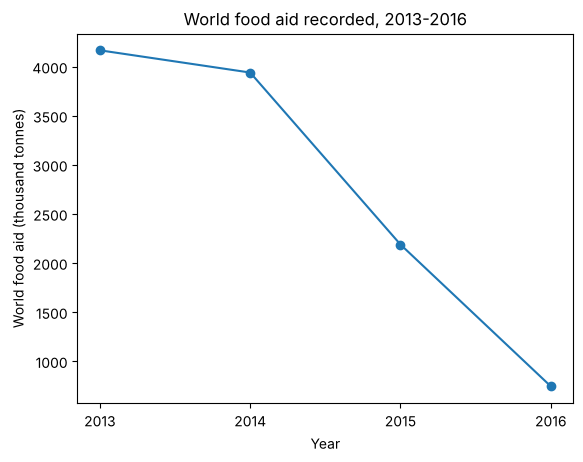

In [41]:
aid_by_year = aide_alimentaire.groupby('Année')['Aide alimentaire'].sum()
plt.plot(aid_by_year.index, aid_by_year / 1e6, marker='o')
plt.xticks(aid_by_year.index)
plt.xlabel('Year')
plt.ylabel('World food aid (thousand tonnes)')
plt.title('World food aid recorded, 2013-2016');

In [42]:
# Correction: computed from the data instead of typed-in values
drop = (aid_by_year[2016] - aid_by_year[2013]) / aid_by_year[2013] * 100
print(f"Recorded food aid: {aid_by_year[2013] / 1e9:.2f} million tonnes in 2013, {aid_by_year[2016] / 1e9:.2f} in 2016 ({drop:.0f} %)")

Recorded food aid: 4.17 million tonnes in 2013, 0.74 in 2016 (-82 %)


**Conclusion:** recorded food aid fell from 4.17 to 0.74 million tonnes between 2013 and 2016, −82%.
Section 5 shows that most of this drop comes from countries that stop appearing in the data.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 5 - A second look at data coverage (added for the portfolio)</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">5.1 - Undernourishment: which countries have no estimate?</h3>
</div>

In [43]:
# A blank value means no estimate; '<0.1' is an estimate (fewer than 100,000 people), so it is not counted here
raw_undernourishment = pd.read_csv('../data/sous_nutrition.csv')
no_estimate = raw_undernourishment.groupby('Zone')['Valeur'].apply(lambda s: s.isna().all())
no_estimate = no_estimate[no_estimate].index

population_no_estimate = population_2017[population_2017['Zone'].isin(no_estimate)]['Population'].sum()
print(f"{len(no_estimate)} countries have no estimate for any period.")
print(f"They are home to {population_no_estimate / 1e9:.2f} billion people, "
      f"{population_no_estimate / world_population_2017 * 100:.0f} % of the world population.")
print(sorted(set(no_estimate) & {'Chine, continentale', 'République démocratique du Congo', 'Yémen', 'Somalie',
                                  'Soudan du Sud', 'République arabe syrienne', 'Ouganda', 'Zambie', 'Zimbabwe',
                                  'République centrafricaine', 'Niger', 'Burundi'}))

96 countries have no estimate for any period.
They are home to 3.33 billion people, 44 % of the world population.
['Burundi', 'Chine, continentale', 'Niger', 'Ouganda', 'République arabe syrienne', 'République centrafricaine', 'République démocratique du Congo', 'Somalie', 'Soudan du Sud', 'Yémen', 'Zambie', 'Zimbabwe']


**Reading:** the fill with 0 in step 2.4 is reasonable for countries such as France or Germany, where undernourishment is very low,
but the countries with no estimate also include some of the hungriest places in the world. **The 535.7 million is therefore a floor**, and the
top 10 of section 3.6 only ranks countries that have an estimate.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">5.2 - Food aid and needs, on comparable countries</h3>
</div>

In [44]:
top_10_aid = aid_by_country.head(10)['Zone']
print('Among the 10 most-aided countries, no undernourishment estimate for:')
print([c for c in top_10_aid if c in set(no_estimate)])

needs_2014 = population_sous_nutrition_2014.set_index('Zone')
aid_vs_needs = aid_2014.set_index('Zone').join(needs_2014[['Sous nutrition', 'Proportion %']], how='inner')
aid_vs_needs = aid_vs_needs[~aid_vs_needs.index.isin(no_estimate)]

rho_number, p_number = spearmanr(aid_vs_needs['Aide alimentaire'], aid_vs_needs['Sous nutrition'])
rho_share, p_share = spearmanr(aid_vs_needs['Aide alimentaire'], aid_vs_needs['Proportion %'])
print(f"\n{len(aid_vs_needs)} recipient countries in 2014 have an undernourishment estimate.")
print(f"Aid vs NUMBER of undernourished people: Spearman rho = {rho_number:.2f} (p = {p_number:.4f})")
print(f"Aid vs SHARE of undernourished people:  Spearman rho = {rho_share:.2f} (p = {p_share:.3f})")

Among the 10 most-aided countries, no undernourishment estimate for:
['République arabe syrienne', 'Yémen', 'Soudan du Sud', 'Somalie', 'République démocratique du Congo', 'Niger']

49 recipient countries in 2014 have an undernourishment estimate.
Aid vs NUMBER of undernourished people: Spearman rho = 0.55 (p = 0.0000)
Aid vs SHARE of undernourished people:  Spearman rho = 0.28 (p = 0.052)


**Reading:** six of the ten most-aided countries have no undernourishment estimate, so they could never appear in the other ranking of section 4.1.
Among recipients that do have an estimate, aid clearly follows the **number** of undernourished people, but not their **share**.
Aid is not disconnected from needs: it goes to large numbers of people and to acute crises, rather than to the highest rates.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">5.3 - World food aid: how many countries report each year?</h3>
</div>

In [45]:
coverage = aide_alimentaire.groupby('Année')['Zone'].nunique()
print(coverage)

aid_pivot = aid_by_country_year.pivot(index='Zone', columns='Année', values='Aide alimentaire')
same_countries = aid_pivot.dropna(subset=[2013, 2016])
same_drop = (same_countries[2016].sum() - same_countries[2013].sum()) / same_countries[2013].sum() * 100
print(f"\nCountries recorded in both 2013 and 2016: {len(same_countries)}")
print(f"Their aid: {same_countries[2013].sum() / 1e9:.2f} million tonnes in 2013, "
      f"{same_countries[2016].sum() / 1e9:.2f} in 2016 ({same_drop:.0f} %)")

Année
2013    72
2014    70
2015    60
2016    26
Name: Zone, dtype: int64

Countries recorded in both 2013 and 2016: 25
Their aid: 1.51 million tonnes in 2013, 0.74 in 2016 (-51 %)


**Reading:** 72 countries have food aid recorded in 2013, but only 26 in 2016. Most of the −82% comes from countries that stop appearing
in the file. On the countries recorded in both years, aid fell by about half: a real decline, but not a collapse.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Conclusion</h2>
</div>

- **The world produces enough food:** the calories available in 2017 could feed about 8.8 billion people, while 535.7 million at least were undernourished.
- **Half of the domestic supply never reaches a plate directly**, and 36% of cereals feed animals.
- **The gap between countries is huge:** 3,625 kcal per person per day on average in the 10 best-supplied countries, 2,060 in the 10 least.
- **Food aid follows crises and the number of hungry people**, but the data on both aid and undernourishment has large gaps, which must be read before drawing conclusions.